### Import Dependencies

In [1]:
from pydantic import BaseModel

from langchain_openai import ChatOpenAI

from langsmith import traceable

from langgraph.graph import StateGraph, START, END, add_messages
from langgraph.prebuilt import ToolNode
from langgraph.types import Command, interrupt


from langchain_core.messages import SystemMessage, convert_to_openai_messages, HumanMessage, AIMessage
from IPython.display import Image, display

from typing import Any, Annotated, List, Literal
from pydantic import Field
from operator import add

from jinja2 import Template

from utils.utils import postprocess_response
from utils.tools import (
    get_formatted_item_context, 
    get_formatted_reviews_context, 
    get_shopping_cart, remove_from_cart, 
    add_to_shopping_cart, 
    check_warehouse_availability, 
    reserve_warehouse_items
)

import re
from typing import Any, Dict

from guardrails import Guard, OnFailAction

from guardrails.validator_base import (
    FailResult,
    PassResult,
    ValidationResult,
    Validator,
    register_validator
)

## Persistent State in Supabase

In [2]:
from langgraph.checkpoint.postgres import PostgresSaver

In [3]:
import os
from dotenv import load_dotenv

load_dotenv("../../.env")
LANGGRAPH_DB_URL = os.environ["LANGGRAPH_DB_URL"]

### Set up the database (once)

In [4]:
with PostgresSaver.from_conn_string(
    LANGGRAPH_DB_URL
) as checkpointer:

    checkpointer.setup()

## Define the MAS

### Global Agent Configs

In [5]:
MAX_ITERATIONS_PRODUCT_QNA = 5
MAX_ITERATIONS_SHOPPING_CART = 4
MAX_ITERATIONS_WAREHOUSE_MANAGER = 4
MAX_ITERATIONS_COORDINATOR = 6

## Worker Agents

### Product QnA Agent

In [6]:
class RAGUsedContext(BaseModel):
    id: str = Field(description="ID of the item used to answer the question")
    description: str = Field(description="Description of the item used to answer the question")

class FinalQnAAgentResponse(BaseModel):

    """Call this tool when the final answer is possible using available context."""

    answer: str = Field(description="Answer to the question")
    references: list[RAGUsedContext] = Field(description="List of items used to answer the question")

In [7]:
@traceable(
    name="product_qna_agent",
    run_type="llm",
    metadata={
        "ls_provider": "openai",
        "ls_model_name": "gpt-5.4-mini"
    }
)
def product_qna_agent(state) -> dict:
    
    prompt_template = """You are a shopping assistant answering customer questions about products in stock.

## Procedure

Before every tool call, check what previous tool calls in this conversation already
returned. Search only for what's genuinely missing. If nothing is missing, call
FinalResponse instead — previously retrieved data is as valid as fresh data, and
re-running a search you already ran is an error.

Customer: "Which of those speakers is cheapest?"
→ Speakers and prices already retrieved. No search. FinalResponse.

Customer: "Does that jacket come with a rain shell, and do you have gloves?"
→ Jacket specs already retrieved; gloves are not. Search gloves only.

## Answering

- Never state a product detail that isn't in the retrieved data.
- Describe products with specifications in bullet points.
- In references, include every chunk that contributed to your answer with the chunk id and product name.
- Call retrieved data "available products", never "context".
- Nothing relevant returned → say so, ask the customer to refine.
- Off-topic question → ask what product they're interested in.
"""

    template = Template(prompt_template)

    prompt = template.render()

    if state.product_qna_agent.iteration == MAX_ITERATIONS_PRODUCT_QNA:
        tools = [FinalQnAAgentResponse]
    else:
        tools = [get_formatted_item_context, get_formatted_reviews_context, FinalQnAAgentResponse]

    llm = ChatOpenAI(
        model="gpt-5.4-mini",
        reasoning_effort="low",
        use_responses_api=True
    )
    llm_with_tools = llm.bind_tools(
        tools,
        tool_choice="required"
    )

    response = llm_with_tools.invoke(
        [
            SystemMessage(content=prompt),
            *state.messages
        ]
    )

    postprocessed_response = postprocess_response(response, "FinalQnAAgentResponse", "product_qna_agent")

    final_answer = postprocessed_response.get("final_answer")
    answer = postprocessed_response.get("answer")
    references = postprocessed_response.get("references")
    response = postprocessed_response.get("response")

    return {
        "messages": [response],
        "product_qna_agent": {
            "iteration": state.product_qna_agent.iteration + 1,
            "final_answer": final_answer
        },
        "answer": answer,
        "references": references
    }

### Shopping Cart Agent

In [9]:
class FinalAgentResponse(BaseModel):

    answer: str = Field(description="Answer to the question")

In [8]:
@traceable(
    name="shopping_cart_agent",
    run_type="llm",
    metadata={
        "ls_provider": "openai",
        "ls_model_name": "gpt-5.4-mini"
    }
)
def shopping_cart_agent(state) -> dict:
    
    prompt_template = """You are a part of the shopping assistant that can manage the user's shopping cart.

## Instructions

- Use names specificly provided in the available tools. Don't add any additional text to the names.
- You can run multipple tools at once.
- If you do not need to perform additional work, output the final answer via the `FinalAgentResponse` tool.
- As the final answer you should return an answer in a form of actions performed.

## Additional information about the user

- User ID: {{ user_id }}
- Cart ID: {{ cart_id }}
"""

    template = Template(prompt_template)

    prompt = template.render(
        user_id=state.user_id,
        cart_id=state.cart_id
    )

    if state.shopping_cart_agent.iteration == MAX_ITERATIONS_SHOPPING_CART:
        tools = [FinalAgentResponse]
    else:
        tools = [get_shopping_cart, remove_from_cart, add_to_shopping_cart, FinalAgentResponse]

    llm = ChatOpenAI(
        model="gpt-5.4-mini",
        reasoning_effort="low",
        use_responses_api=True
    )
    llm_with_tools = llm.bind_tools(
        tools,
        tool_choice="required"
    )

    response = llm_with_tools.invoke(
        [
            SystemMessage(content=prompt),
            AIMessage(content=state.coordinator_agent.next_agent_task),
            *state.shopping_cart_agent.messages
        ]
    )

    postprocessed_response = postprocess_response(response, "FinalAgentResponse", "shopping_cart_agent")

    final_answer = postprocessed_response.get("final_answer")
    answer = postprocessed_response.get("answer")
    response = postprocessed_response.get("response")

    return {
        "messages": [response] if final_answer else [],
        "shopping_cart_agent": {
            "iteration": state.shopping_cart_agent.iteration + 1,
            "final_answer": final_answer,
            "messages": [response]
        },
        "answer": answer
    }

### Shopping Cart Agent Human in The Loop Node

In [10]:
def hitl_add_to_cart(state) -> Command[Literal["shopping_cart_agent_tool_node", END]]:

    for tool_call in state.shopping_cart_agent.messages[-1].tool_calls:
        if tool_call.get("name") == "add_to_shopping_cart":
            items_to_add = tool_call.get("args").get("items")
            break

    human_input = interrupt(
        {
            "items_to_add": items_to_add
        }
    )

    ### ALWAYS PAUSES HERE

    if human_input.get("confirmed"):
        return Command(
            update={},
            goto = "shopping_cart_agent_tool_node"
        )
    else:
        last_msg = state.shopping_cart_agent.messages[-1]
        sanitized_msg = AIMessage(
            content=last_msg.content,
            id=last_msg.id
        )

        return Command(
            update={
                "shopping_cart_agent": {
                    "messages": [sanitized_msg]
                },
                "answer": "You have rejected the addition of items to the cart."
            },
            goto = END
        )

### Warehouse Manager Agent

In [11]:
@traceable(
    name="warehouse_manager_agent",
    run_type="llm",
    metadata={
        "ls_provider": "openai",
        "ls_model_name": "gpt-5.4-mini"
    }
)
def warehouse_manager_agent(state) -> dict:
    
    prompt_template = """You are a part of the shopping assistant that can manage available inventory in the warehouses.

## Instructions

- As the final answer you should return an answer to the users query in a form of actions performed.
- You must always check the availability of the items in the warehouses before reserving them.
- Only reserve items in warehouses if entire order can be reserved or the user has confirmed that they want a partial reservation.
- If you cannot reserve any items, return an answer that the order cannot be reserved.
- If you can reserve some items, return an answer that the order can be partially reserved and include the details.
- If only partial quantity can be reserved in some warehouses, try to combine the required quantity from different warehouses.
- Try to reserve items from the closest warehouse to the user first if users location is provided.
- If you do not need to perform additional work, output the final answer via the `FinalAgentResponse` tool.
- As the final answer you should return an answer in a form of actions performed.
"""

    template = Template(prompt_template)

    prompt = template.render()

    if state.warehouse_manager_agent.iteration == MAX_ITERATIONS_WAREHOUSE_MANAGER:
        tools = [FinalAgentResponse]
    else:
        tools = [check_warehouse_availability, reserve_warehouse_items, FinalAgentResponse]

    llm = ChatOpenAI(
        model="gpt-5.4-mini",
        reasoning_effort="low",
        use_responses_api=True
    )
    llm_with_tools = llm.bind_tools(
        tools,
        tool_choice="required"
    )

    response = llm_with_tools.invoke(
        [
            SystemMessage(content=prompt),
            AIMessage(content=state.coordinator_agent.next_agent_task),
            *state.warehouse_manager_agent.messages
        ]
    )

    postprocessed_response = postprocess_response(response, "FinalAgentResponse", "warehouse_manager_agent")

    final_answer = postprocessed_response.get("final_answer")
    answer = postprocessed_response.get("answer")
    response = postprocessed_response.get("response")

    return {
        "messages": [response] if final_answer else [],
        "warehouse_manager_agent": {
            "iteration": state.warehouse_manager_agent.iteration + 1,
            "final_answer": final_answer,
            "messages": [response]
        },
        "answer": answer
    }

## Coordinator Agent

In [12]:
class Plan(BaseModel):
    next_agent: str = Field(description="The next agent to invoke")
    next_agent_task: str = Field(description="The task to be performed by the next agent")

In [13]:
@traceable(
    name="coordinator_agent",
    run_type="llm",
    metadata={
        "ls_provider": "openai",
        "ls_model_name": "gpt-5.4-mini"
    }
)
def coordinator_agent(state) -> dict:
    
    prompt_template = """You are a Coordinator Agent as part of a shopping assistant.

## Instructions

- Your role is to delegate work to worker agents in order to solve user queries.
- You should output the next agent to invoke.
- Once an agent finishes its task, you will be handed the control back, you should then review the conversation history and output the next delegation via the `Plan` tool.
- If you do not need to delegate work to any agent, output the final answer via the `FinalAgentResponse` tool.
- Do not route to any agent if the user's query needs clarification or is irelevant. Do it yourself.
- Only route to the `warehouse_manager_agent` if the user has confirmed that they want to reserve an item and it was already successfully added to the shopping cart.
- Only route to the `shopping_cart_agent` if the user specifically asks about their shopping cart or wants to add or remove items from the shopping cart.
- Do not delegate work to the same agent twice in a row.

## Routing rules

Match the user's latest message to one of these patterns:

1. PRODUCT QUESTION — asks about products, specs, reviews, availability, suggestions.
    Examples: "can I get some earphones", "show me laptops", "what watches do you have", "tell me about X", "is X any good", "I'd like to see some X".
    → Route ONLY to `product_qna_agent`. When it returns, emit `FinalAgentResponse`. Do NOT chain to cart or warehouse.

2. EXPLICIT CART INSTRUCTION — uses cart vocabulary.
    Examples: "add to my cart", "remove from my cart", "what's in my cart", "put X in my cart", "delete X from cart".
    → Route to `shopping_cart_agent`. (If items must be discovered first, route to `product_qna_agent` first.)

3. EXPLICIT RESERVATION INSTRUCTION — uses warehouse/reservation vocabulary.
    Examples: "reserve these", "hold these for me", "check warehouse stock for X".
    → Route to `warehouse_manager_agent` ONLY AFTER items are confirmed in the cart.

Default rule: if the user's message does NOT contain explicit cart or warehouse vocabulary, do NOT delegate to those agents. Phrases like "can I get", "I want",
"I'd like", "show me", "I need" are PRODUCT QUESTIONS, not purchase instructions. The user must explicitly say "add", "cart", "reserve", "buy", or "order" before those agents are in scope.

## Available agents and skills
 
### `product_qna_agent`
 
Owns all product knowledge: catalog, specs, pricing, reviews, recommendations. This is the default agent for any question about what exists or what to buy.
 
Skills:
 
- `get_formatted_item_context` — Search available products and return the top k matching inventory items.
- `get_formatted_reviews_context` — Get the top k reviews matching a query for a list of prefiltered items.
Does not: modify the cart, check warehouse stock, or reserve anything.
 
### `shopping_cart_agent`
 
Owns the state of the user's shopping cart.
 
Skills:
 
- `add_to_shopping_cart` — Add a list of provided items to the shopping cart.
- `get_shopping_cart` — Retrieve all items in a user's shopping cart.
- `remove_from_cart` —  Remove an item completely from the shopping cart.
Does not: recommend products, check warehouse stock, reserve stock, or place orders.
 
### `warehouse_manager_agent`
 
Owns warehouse inventory and reservations.
 
Skills:
 
- `check_warehouse_availability` — Check availability of items across warehouses, including partial fulfillment options.
- `reserve_warehouse_items` — Reserve items from multiple warehouses in a single transaction.
Does not: recommend products, modify the cart.
"""

    template = Template(prompt_template)

    prompt = template.render()

    if state.coordinator_agent.iteration == MAX_ITERATIONS_COORDINATOR:
        tools = [FinalAgentResponse]
    else:
        tools = [Plan, FinalAgentResponse]

    llm = ChatOpenAI(
        model="gpt-5.4-mini",
        reasoning_effort="medium",
        use_responses_api=True
    )
    llm_with_tools = llm.bind_tools(
        tools,
        tool_choice="required"
    )

    response = llm_with_tools.invoke(
        [
            SystemMessage(content=prompt),
            *state.messages
        ]
    )

    final_answer = False
    answer = ""
    next_agent = ""
    next_agent_task = ""

    if len(response.tool_calls) > 0:
        if response.tool_calls[0].get("name") == "Plan":
            next_agent = response.tool_calls[0].get("args").get("next_agent")
            next_agent_task = response.tool_calls[0].get("args").get("next_agent_task")
            response = AIMessage(content=f"[coordinator_agent decision] Next agent: {next_agent}. Next agent task: {next_agent_task}")
        else:
            postprocessed_response = postprocess_response(response, "FinalAgentResponse")

            final_answer = postprocessed_response.get("final_answer")
            answer = postprocessed_response.get("answer")
            response = postprocessed_response.get("response")

    return {
        "messages": [response] if response else [],
        "coordinator_agent": {
            "iteration": state.coordinator_agent.iteration + 1,
            "final_answer": final_answer,
            "next_agent": next_agent,
            "next_agent_task": next_agent_task
        },
        "answer": answer
    }

### Product ID Redaction Guardrail Node

In [14]:
PRODUCT_ID = re.compile(r"\bB0[A-Z0-9]{8}\b")
REPLACEMENT = "[REDACTED..]"

In [15]:
@register_validator(name="redact_product_id", data_type="string")
class RedactProductID(Validator):

    def _validate(self, value: Any, metadata: Dict[str, Any] = {}) -> ValidationResult:

        matches = PRODUCT_ID.findall(value)

        if matches:
            return FailResult(
                error_message=f"found {len(matches)} product ids: {matches}",
                fix_value=PRODUCT_ID.sub(REPLACEMENT, value)
            )

        return PassResult()

In [16]:
@traceable(
    name="redact_product_id"
)
def redact_product_id(state) -> dict:
    
    guard = Guard().use(RedactProductID(on_fail=OnFailAction.FIX))
    guardrailed_answer = guard.validate(state.answer)

    return {
        "answer": guardrailed_answer.validated_output
    }

### Router Nodes

In [17]:
def product_qna_agent_tool_router(state) -> str:

    if state.product_qna_agent.final_answer:
        return "end"
    elif state.product_qna_agent.iteration > MAX_ITERATIONS_PRODUCT_QNA:
        return "end"
    elif len(state.messages[-1].tool_calls) > 0:
        return "tools"
    else:
        return "end"

In [18]:
def shopping_cart_agent_tool_router(state) -> str:

    add_to_cart_tool_call = False
    for tool_call in state.shopping_cart_agent.messages[-1].tool_calls:
        if tool_call.get("name") == "add_to_shopping_cart":
            add_to_cart_tool_call = True
            break

    if state.shopping_cart_agent.final_answer:
        return "end"
    elif state.shopping_cart_agent.iteration > MAX_ITERATIONS_SHOPPING_CART:
        return "end"
    elif len(state.shopping_cart_agent.messages[-1].tool_calls) > 0:
        if add_to_cart_tool_call:
            return "hitl_add_to_cart"
        else:
            return "tools"
    else:
        return "end"

In [19]:
def warehouse_manager_agent_tool_router(state) -> str:

    if state.warehouse_manager_agent.final_answer:
        return "end"
    elif state.warehouse_manager_agent.iteration > MAX_ITERATIONS_WAREHOUSE_MANAGER:
        return "end"
    elif len(state.warehouse_manager_agent.messages[-1].tool_calls) > 0:
        return "tools"
    else:
        return "end"

In [20]:
def coordinator_agent_edge(state) -> str:

    if state.coordinator_agent.final_answer:
        return "end"
    elif state.coordinator_agent.iteration > MAX_ITERATIONS_COORDINATOR:
        return "end"
    elif state.coordinator_agent.next_agent == "product_qna_agent":
        return "product_qna_agent"
    elif state.coordinator_agent.next_agent == "shopping_cart_agent":
        return "shopping_cart_agent"
    elif state.coordinator_agent.next_agent == "warehouse_manager_agent":
        return "warehouse_manager_agent"
    else:
        return "end"

### Graph Construction

In [21]:
class AgentProperties(BaseModel):
    iteration: int = 0
    final_answer: bool = False
    messages: Annotated[List[Any], add_messages] = []

class CoordinatorAgentProperties(BaseModel):
    iteration: int = 0
    final_answer: bool = False
    next_agent: str = ""
    next_agent_task: str = ""
    
class State(BaseModel):
    messages: Annotated[List[Any], add] = []
    user_intent: str = ""
    product_qna_agent: AgentProperties = AgentProperties()
    shopping_cart_agent: AgentProperties = AgentProperties()
    warehouse_manager_agent: AgentProperties = AgentProperties()
    coordinator_agent: CoordinatorAgentProperties = CoordinatorAgentProperties()
    answer: str = ""
    references: list[RAGUsedContext] = []
    user_id: str = ""
    cart_id: str = ""

In [22]:
workflow = StateGraph(State)

product_qna_agent_tools = [get_formatted_item_context, get_formatted_reviews_context]
product_qna_agent_tool_node = ToolNode(product_qna_agent_tools)

shopping_cart_agent_tools = [get_shopping_cart, remove_from_cart, add_to_shopping_cart]
_shopping_cart_agent_tool_node = ToolNode(shopping_cart_agent_tools)

def shopping_cart_agent_tool_node(state):

    agent_local_state = state.shopping_cart_agent
    output = _shopping_cart_agent_tool_node.invoke({"messages": state.shopping_cart_agent.messages})

    return {
        "shopping_cart_agent": agent_local_state.model_copy(
            update={
                "messages": agent_local_state.messages + output["messages"]
            }
        )
    }

warehouse_manager_agent_tools = [check_warehouse_availability, reserve_warehouse_items]
_warehouse_manager_agent_tool_node = ToolNode(warehouse_manager_agent_tools)

def warehouse_manager_agent_tool_node(state):

    agent_local_state = state.warehouse_manager_agent
    output = _warehouse_manager_agent_tool_node.invoke({"messages": state.warehouse_manager_agent.messages})

    return {
        "warehouse_manager_agent": agent_local_state.model_copy(
            update={
                "messages": agent_local_state.messages + output["messages"]
            }
        )
    }

workflow.add_node("product_qna_agent_tool_node", product_qna_agent_tool_node)
workflow.add_node("shopping_cart_agent_tool_node", shopping_cart_agent_tool_node)
workflow.add_node("warehouse_manager_agent_tool_node", warehouse_manager_agent_tool_node)
workflow.add_node("product_qna_agent", product_qna_agent)
workflow.add_node("shopping_cart_agent", shopping_cart_agent)
workflow.add_node("warehouse_manager_agent", warehouse_manager_agent)
workflow.add_node("coordinator_agent", coordinator_agent)

workflow.add_node("hitl_add_to_cart", hitl_add_to_cart)

workflow.add_node("redact_product_id", redact_product_id)

workflow.add_edge(START, "coordinator_agent")

workflow.add_conditional_edges(
    "coordinator_agent",
    coordinator_agent_edge,
    {
        "product_qna_agent": "product_qna_agent",
        "shopping_cart_agent": "shopping_cart_agent",
        "warehouse_manager_agent": "warehouse_manager_agent",
        "end": "redact_product_id"
    }
)

workflow.add_conditional_edges(
    "product_qna_agent",
    product_qna_agent_tool_router,
    {
        "tools": "product_qna_agent_tool_node",
        "end": "coordinator_agent"
    }
)

workflow.add_conditional_edges(
    "shopping_cart_agent",
    shopping_cart_agent_tool_router,
    {
        "tools": "shopping_cart_agent_tool_node",
        "hitl_add_to_cart": "hitl_add_to_cart",
        "end": "coordinator_agent"
    }
)

workflow.add_conditional_edges(
    "warehouse_manager_agent",
    warehouse_manager_agent_tool_router,
    {
        "tools": "warehouse_manager_agent_tool_node",
        "end": "coordinator_agent"
    }
)

workflow.add_edge("product_qna_agent_tool_node", "product_qna_agent")
workflow.add_edge("shopping_cart_agent_tool_node", "shopping_cart_agent")
workflow.add_edge("warehouse_manager_agent_tool_node", "warehouse_manager_agent")
workflow.add_edge("redact_product_id", END)

graph = workflow.compile()

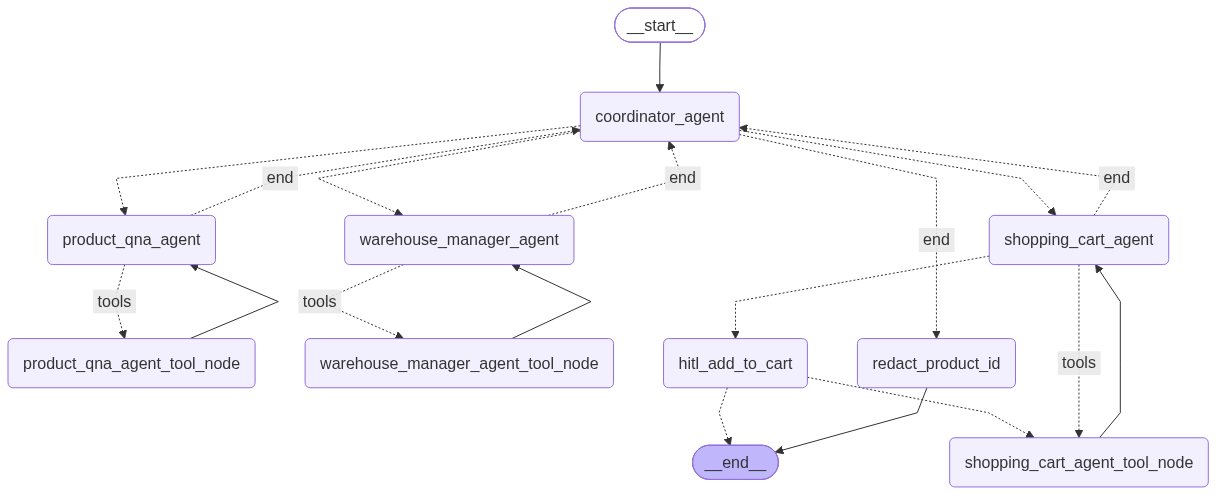

In [23]:
display(Image(graph.get_graph().draw_mermaid_png()))

## Test the Agent

In [24]:
from langgraph.checkpoint.postgres import PostgresSaver

### Multiturn Conversation

In [25]:
initial_state = {
    "messages": [HumanMessage(content="Can you suggest me some laptops? And be sure to include product IDs with your answer.")],
    "user_id": "supabase-test-01",
    "cart_id": "supabase-test-01"
}
config = {
    "configurable": {
        "thread_id": "supabase-test-01"
    }
}

with PostgresSaver.from_conn_string(
    LANGGRAPH_DB_URL
) as checkpointer:

    graph = workflow.compile(checkpointer=checkpointer)

    for chunk in graph.stream(
        initial_state,
        config=config,
        stream_mode=["values", "debug"]
    ):
        print(chunk)
        result_1 = chunk[1]

('debug', {'step': -1, 'timestamp': '2026-11-04T11:30:19.696295+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'supabase-test-01', 'checkpoint_id': '1f1d8431-da48-6d74-bfff-d3c218ff6eda'}}, 'parent_config': None, 'values': {'messages': []}, 'metadata': {'source': 'input', 'step': -1, 'parents': {}}, 'next': ['__start__'], 'tasks': [{'id': '3b9802d6-1543-08b8-d8e6-3dc1322b57df', 'name': '__start__', 'interrupts': (), 'state': None}]}})
('values', {'messages': [HumanMessage(content='Can you suggest me some laptops? And be sure to include product IDs with your answer.', additional_kwargs={}, response_metadata={})], 'user_id': 'supabase-test-01', 'cart_id': 'supabase-test-01'})
('debug', {'step': 0, 'timestamp': '2026-11-04T11:30:19.697604+00:00', 'type': 'checkpoint', 'payload': {'config': {'configurable': {'checkpoint_ns': '', 'thread_id': 'supabase-test-01', 'checkpoint_id': '1f1d8431-da54-605c-8000-4d9ec2845338'}}, 'parent_config

/Users/hang/Documents/Development/ai-eng-course/ai-eng-project/.venv/lib/python3.12/site-packages/qdrant_client/qdrant_remote.py:290: UserWarning: Failed to obtain server version. Unable to check client-server compatibility. Set check_compatibility=False to skip version check.
  show_warning(


ResponseHandlingException: [Errno 61] Connection refused

In [ ]:
result_1

In [ ]:
print(result_1["payload"]["values"]["answer"])

In [ ]:
initial_state = {
    "messages": [HumanMessage(content="Add HP 17.3' Flagship HD+ Business Laptop to my cart")],
    "user_id": "supabase-test-01",
    "cart_id": "supabase-test-01"
}
config = {
    "configurable": {
        "thread_id": "supabase-test-01"
    }
}

with PostgresSaver.from_conn_string(
    LANGGRAPH_DB_URL
) as checkpointer:

    graph = workflow.compile(checkpointer=checkpointer)

    for chunk in graph.stream(
        initial_state,
        config=config,
        stream_mode=["values", "debug"]
    ):
        print(chunk)
        result_2 = chunk[1]

In [ ]:
initial_state = Command(
    resume={
        "confirmed": False
    }
)
config = {
    "configurable": {
        "thread_id": "supabase-test-01"
    }
}

with PostgresSaver.from_conn_string(
    LANGGRAPH_DB_URL
) as checkpointer:

    graph = workflow.compile(checkpointer=checkpointer)

    for chunk in graph.stream(
        initial_state,
        config=config,
        stream_mode=["values", "debug"]
    ):
        print(chunk)
        result_3 = chunk[1]

In [ ]:
print(result_3["payload"]["values"]["answer"])